# 📌 Handling JSON Files in PySpark

### Q. What is JSON?

- JSON (JavaScript Object Notation) is a widely used format for storing and exchanging data.

- It consists of key-value pairs and supports nested structures such as dictionaries and lists.

## 🔹 Types of JSON Files

### 1️⃣ Simple JSON (Flat Structure)

- Data is stored as key-value pairs.

- No nested objects or lists.

- A simple JSON file contains flat data (no nesting).

- Each employee has id, name, age, and department as separate fields.

In [ ]:
# Example

[
  {"id": 1, "name": "Alice", "age": 30, "department": "HR"},
  {"id": 2, "name": "Bob", "age": 25, "department": "IT"},
  {"id": 3, "name": "Charlie", "age": null, "department": "Finance"}
]


➡ Each object represents an employee with columns like id, name, age, and department.

### 2️⃣ Nested JSON (Complex Structure)

- Contains dictionaries (objects) and lists (arrays) inside records.

- Requires flattening for analysis.

- A nested JSON file contains sub-objects (dictionaries) and lists (arrays) inside each record.

- Here, employees have:

- contact details inside a dictionary {email, phone}

- projects stored as a list [project_id, name]

In [ ]:
# Example

[
  {
    "id": 1,
    "name": "Alice",
    "contact": {
      "email": "alice@example.com",
      "phone": "1234567890"
    },
    "projects": [
      {"project_id": 101, "name": "Project A"},
      {"project_id": 102, "name": "Project B"}
    ]
  },
  {
    "id": 2,
    "name": "Bob",
    "contact": {
      "email": "bob@example.com",
      "phone": "9876543210"
    },
    "projects": [
      {"project_id": 103, "name": "Project C"}
    ]
  }
]

➡ Here, contact is a nested dictionary, and projects is a list of dictionaries.

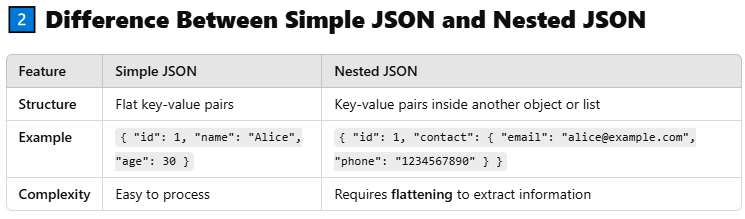

### Read simple json and Display Its Schema

In [ ]:
# JSON is semi-structured, and Spark automatically detects the schema.

In [1]:
pip install pyspark

In [2]:
import pyspark

In [3]:
from pyspark.sql import SparkSession

In [4]:
spark = SparkSession.builder.getOrCreate()

In [ ]:
df = spark.read.json('/content/employees.json')
df.show()

AnalysisException: Since Spark 2.3, the queries from raw JSON/CSV files are disallowed when the
referenced columns only include the internal corrupt record column
(named _corrupt_record by default). For example:
spark.read.schema(schema).csv(file).filter($"_corrupt_record".isNotNull).count()
and spark.read.schema(schema).csv(file).select("_corrupt_record").show().
Instead, you can cache or save the parsed results and then send the same query.
For example, val df = spark.read.schema(schema).csv(file).cache() and then
df.filter($"_corrupt_record".isNotNull).count().

In [ ]:
df = spark.read.option('header', 'true')\
.option('multiline', 'true')\
.option('inferSchema', 'true')\
.format('json')\
.load('/content/employees.json')


In [ ]:
# df = spark.read.json('/content/employees.json', header=True, inferSchema=True, multiline=True)

In [ ]:
df.show()
df.printSchema()

+----+----------+---+-------+
| age|department| id|   name|
+----+----------+---+-------+
|  30|        HR|  1|  Alice|
|  25|        IT|  2|    Bob|
|NULL|   Finance|  3|Charlie|
+----+----------+---+-------+

root
 |-- age: long (nullable = true)
 |-- department: string (nullable = true)
 |-- id: long (nullable = true)
 |-- name: string (nullable = true)



In [ ]:
df.withColumnRenamed('age', 'AGE')

In [ ]:
df.withColumn('seniority', when(df.age < 26, 'Junior')\
              .when(df.age > 26, 'Senior')\
              .otherwise())

In [ ]:
df.filter(df.age > 25).show()
df.dropa()
df.fillna({"age":0})
df.dropDuplicates()
df.withColumn('new_col', concat_ws('-','col1','col2'))

In [ ]:
df = spark.read.option("multiline", "true").json("/content/employees.json")

df.printSchema()
df.show()


root
 |-- age: long (nullable = true)
 |-- department: string (nullable = true)
 |-- id: long (nullable = true)
 |-- name: string (nullable = true)

+----+----------+---+-------+
| age|department| id|   name|
+----+----------+---+-------+
|  30|        HR|  1|  Alice|
|  25|        IT|  2|    Bob|
|NULL|   Finance|  3|Charlie|
+----+----------+---+-------+



### 📌 3️⃣ Applying Transformations on JSON Data

Once the JSON file is loaded into a DataFrame, various transformations can be applied.

In [ ]:
# A. Selecting Specific Columns

df.select("name", "department").show()

+-------+----------+
|   name|department|
+-------+----------+
|  Alice|        HR|
|    Bob|        IT|
|Charlie|   Finance|
+-------+----------+



In [ ]:
# B. Filtering Data

df.filter(df.age > 25).show()

+---+----------+---+-----+
|age|department| id| name|
+---+----------+---+-----+
| 30|        HR|  1|Alice|
+---+----------+---+-----+



In [ ]:
# C. Handling NULL Values (fillna(), dropna())

df.fillna({"age": 0}).show()  # Replace NULL age with 0
df.dropna().show()  # Drop rows with NULL values

+---+----------+---+-------+
|age|department| id|   name|
+---+----------+---+-------+
| 30|        HR|  1|  Alice|
| 25|        IT|  2|    Bob|
|  0|   Finance|  3|Charlie|
+---+----------+---+-------+

+---+----------+---+-----+
|age|department| id| name|
+---+----------+---+-----+
| 30|        HR|  1|Alice|
| 25|        IT|  2|  Bob|
+---+----------+---+-----+



In [ ]:
# D. Adding New Columns (withColumn())

from pyspark.sql.functions import lit

df = df.withColumn("salary", lit(5000))  # Add a new column with a default salary
df.show()

+----+-------+---+-------+------+
| age|   dept| id|   name|salary|
+----+-------+---+-------+------+
|  30|     HR|  1|  Alice|  5000|
|  25|     IT|  2|    Bob|  5000|
|NULL|Finance|  3|Charlie|  5000|
+----+-------+---+-------+------+



In [ ]:
# E. Renaming Columns (withColumnRenamed())

df = df.withColumnRenamed("department", "dept")
df.show()

+----+-------+---+-------+------+
| age|   dept| id|   name|salary|
+----+-------+---+-------+------+
|  30|     HR|  1|  Alice|  5000|
|  25|     IT|  2|    Bob|  5000|
|NULL|Finance|  3|Charlie|  5000|
+----+-------+---+-------+------+



In [ ]:
# F. Aggregations

from pyspark.sql.functions import avg, count

df.groupBy("dept").agg(avg("age").alias("avg_age"), count("id").alias("num_employees")).show()


+-------+-------+-------------+
|   dept|avg_age|num_employees|
+-------+-------+-------------+
|     HR|   30.0|            1|
|Finance|   NULL|            1|
|     IT|   25.0|            1|
+-------+-------+-------------+



In [ ]:
df2.show()

+----+----------+---+-------+
| age|department| id|   name|
+----+----------+---+-------+
|  30|        HR|  1|  Alice|
|  25|        IT|  2|    Bob|
|NULL|   Finance|  3|Charlie|
+----+----------+---+-------+



In [ ]:
from pyspark.sql.functions import lit

In [ ]:
df2 = df.withColumn('country', lit('US'))
df2.show()

+----+----------+---+-------+-------+
| age|department| id|   name|country|
+----+----------+---+-------+-------+
|  30|        HR|  1|  Alice|     US|
|  25|        IT|  2|    Bob|     US|
|NULL|   Finance|  3|Charlie|     US|
+----+----------+---+-------+-------+



In [ ]:
/content/nested_employees.json

In [ ]:
df2.write.csv("/content/processed_data/")

In [ ]:
# G. Writing Transformed Data to JSON
#/content/output_json
df2.write.csv("/content/target_folder_cleaned_data")

In [ ]:
df2.write.mode("overwrite").parquet("/content/fourth_output_json")

# target_folder_cleaned_data = "/content/target_folder_cleaned_data"

📌 4️⃣ Interview Questions on JSON in PySpark

Here are some common interview questions along with answers:

Basic Questions

❓ 1. How do you read a JSON file in PySpark?
✅ Use spark.read.json("path/to/json") to read JSON data into a DataFrame.

❓ 2. How do you handle missing values in a JSON file?
✅ Use dropna() to remove NULL values or fillna() to replace them.


Intermediate Questions

❓ 3. How do you extract specific fields from a nested JSON structure?
✅ Use df.select("column_name.sub_field") or explode() if it's an array.


❓ 4. What are the common transformations applied on JSON data?
✅ Column selection, filtering, grouping, handling NULL values, and renaming columns.


Advanced Questions

❓ 5. How do you handle deeply nested JSON files in PySpark?
✅ Use explode() and selectExpr() to flatten JSON structures.


❓ 6. How do you write a transformed DataFrame back to JSON?
✅ Use df.write.json("output_path").

# 📌 Handling Nested JSON in PySpark

Many real-world JSON files contain nested structures, such as arrays, dictionaries (maps), or deeply nested fields. PySpark provides functions like explode() and selectExpr() to handle such cases.

In [ ]:
# Example of a Deeply Nested JSON File
 [
  {
    "id": 1,
    "name": "Alice",
    "contact": {
      "email": "alice@example.com",
      "phone": "1234567890"
    },
    "projects": [
      {"project_id": 101, "name": "Project A"},
      {"project_id": 102, "name": "Project B"}
    ]
  },
  {
    "id": 2,
    "name": "Bob",
    "contact": {
      "email": "bob@example.com",
      "phone": "9876543210"
    },
    "projects": [
      {"project_id": 103, "name": "Project C"}
    ]
  }
]


### Reading the Nested JSON File

In [ ]:
from pyspark.sql import SparkSession

spark = SparkSession.builder.appName("NestedJSON").getOrCreate()

In [13]:
# Read JSON file
df = spark.read.json("/content/nested_employees.json")

df.printSchema()  # Check schema to see nested fields
df.show(truncate=False)

root
 |-- _corrupt_record: string (nullable = true)



AnalysisException: Since Spark 2.3, the queries from raw JSON/CSV files are disallowed when the
referenced columns only include the internal corrupt record column
(named _corrupt_record by default). For example:
spark.read.schema(schema).csv(file).filter($"_corrupt_record".isNotNull).count()
and spark.read.schema(schema).csv(file).select("_corrupt_record").show().
Instead, you can cache or save the parsed results and then send the same query.
For example, val df = spark.read.schema(schema).csv(file).cache() and then
df.filter($"_corrupt_record".isNotNull).count().

In [14]:

df = spark.read.option('multiline', 'true').json("/content/nested_employees.json")
df.show()
df.printSchema()

+--------------------+---+-----+--------------------+
|             contact| id| name|            projects|
+--------------------+---+-----+--------------------+
|{alice@example.co...|  1|Alice|[{Project A, 101}...|
|{bob@example.com,...|  2|  Bob|  [{Project C, 103}]|
+--------------------+---+-----+--------------------+

root
 |-- contact: struct (nullable = true)
 |    |-- email: string (nullable = true)
 |    |-- phone: string (nullable = true)
 |-- id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- projects: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- name: string (nullable = true)
 |    |    |-- project_id: long (nullable = true)



In [15]:
df.show(truncate=False)

+-------------------------------+---+-----+------------------------------------+
|contact                        |id |name |projects                            |
+-------------------------------+---+-----+------------------------------------+
|{alice@example.com, 1234567890}|1  |Alice|[{Project A, 101}, {Project B, 102}]|
|{bob@example.com, 9876543210}  |2  |Bob  |[{Project C, 103}]                  |
+-------------------------------+---+-----+------------------------------------+



The schema shows nested structures (contact as a struct, projects as an array of structs).

###  Flattening Nested JSON Fields

A. Extracting Nested Struct Fields

We can extract contact.email and contact.phone using selectExpr().

In [ ]:
df.selectExpr("id","name","contact.email").show()

+---+-----+-----------------+
| id| name|            email|
+---+-----+-----------------+
|  1|Alice|alice@example.com|
|  2|  Bob|  bob@example.com|
+---+-----+-----------------+



In [ ]:
df.selectExpr("id","name", "contact.phone").show()

+---+-----+----------+
| id| name|     phone|
+---+-----+----------+
|  1|Alice|1234567890|
|  2|  Bob|9876543210|
+---+-----+----------+



In [ ]:
df.selectExpr("id","name","contact.email","contact.phone").show()

+---+-----+-----------------+----------+
| id| name|            email|     phone|
+---+-----+-----------------+----------+
|  1|Alice|alice@example.com|1234567890|
|  2|  Bob|  bob@example.com|9876543210|
+---+-----+-----------------+----------+



In [ ]:
df.selectExpr("id", "name", "projects.project_id").show()

+---+-----+----------+
| id| name|project_id|
+---+-----+----------+
|  1|Alice|[101, 102]|
|  2|  Bob|     [103]|
+---+-----+----------+



In [ ]:
df.selectExpr("name","projects.name").show(truncate=False)

+-----+----------------------+
|name |name                  |
+-----+----------------------+
|Alice|[Project A, Project B]|
|Bob  |[Project C]           |
+-----+----------------------+



### Explode

In [20]:
df.show(truncate=False)

+-------------------------------+---+-----+------------------------------------+
|contact                        |id |name |projects                            |
+-------------------------------+---+-----+------------------------------------+
|{alice@example.com, 1234567890}|1  |Alice|[{Project A, 101}, {Project B, 102}]|
|{bob@example.com, 9876543210}  |2  |Bob  |[{Project C, 103}]                  |
+-------------------------------+---+-----+------------------------------------+



In [17]:
df.printSchema()

root
 |-- contact: struct (nullable = true)
 |    |-- email: string (nullable = true)
 |    |-- phone: string (nullable = true)
 |-- id: long (nullable = true)
 |-- name: string (nullable = true)
 |-- projects: array (nullable = true)
 |    |-- element: struct (containsNull = true)
 |    |    |-- name: string (nullable = true)
 |    |    |-- project_id: long (nullable = true)



In [21]:
# Exploding Arrays in JSON (explode())
# The projects field is an array. To extract each project as a separate row, use explode().


from pyspark.sql.functions import explode

df = df.select("id","name", explode("projects").alias("project-details"))

df.show()


+---+-----+----------------+
| id| name| project-details|
+---+-----+----------------+
|  1|Alice|{Project A, 101}|
|  1|Alice|{Project B, 102}|
|  2|  Bob|{Project C, 103}|
+---+-----+----------------+



In [ ]:
df_exploded.show(truncate=False)

In [25]:
# Now, extract individual fields (project_id, name).

df.select('id','name','project-details.name','project-details.project_id').show()

+---+-----+---------+----------+
| id| name|     name|project_id|
+---+-----+---------+----------+
|  1|Alice|Project A|       101|
|  1|Alice|Project B|       102|
|  2|  Bob|Project C|       103|
+---+-----+---------+----------+



In [ ]:
# Writing Transformed DataFrame Back to JSON
# After transformations, save the cleaned data:

df_exploded.write.json("/home/output1.json")

Interview Questions on Handling Nested JSON

Basic

❓ 1. How do you read a JSON file with nested fields?

✅ Use spark.read.json("path"), then check schema using printSchema().

Intermediate

❓ 2. How do you extract a specific field from a nested JSON column?

✅ Use selectExpr("column.nested_field") or df.select(df.column.nested_field).

❓ 3. How do you handle an array field in JSON?

✅ Use explode(column_name) to flatten array elements.

Advanced

❓ 4. How do you handle a JSON file with multiple levels of nesting?

✅ Use multiple explode() calls and selectExpr() to flatten deeply nested structures.

❓ 5. How do you write transformed JSON data back to a file?

✅ Use df.write.json("output_path").



In [ ]:
❓ 2. Why can't we directly read nested JSONs into PySpark like a CSV file?
✅ Answer:

CSV files have a tabular format (rows & columns), while nested JSONs contain hierarchical data.

PySpark loads JSON but keeps nested structures intact, so we must manually extract them.

📌 Example Issue:

If we read nested_employees.json, it won’t give email directly. Instead, it shows:

|-- contact: struct (nullable = true)

✔ Solution: We use select() to extract nested fields.

In [ ]:
# Q. How would you extract the email field from nested_employees.json in PySpark?
# Answer:
# Use the dot notation (.) in select() to extract the email field from the contact struct.

df_nested = spark.read.json("path/to/nested_employees.json")
df_email = df_nested.select("id", "name", "contact.email")
df_email.show(truncate=False)

In [ ]:
# Q. How do you handle a list of projects in JSON while reading in PySpark?
# Answer:

The projects field is an array inside JSON.

We use explode() to convert each item in the list into a separate row.

# Example (Flatten projects field)


from pyspark.sql.functions import explode

df_projects = df_nested.select("id", "name", explode("projects").alias("project_details"))
df_projects_final = df_projects.select("id", "name", "project_details.project_id", "project_details.name")
df_projects_final.show()

# **Reading Modes in PySpark**

When you use spark.read (DataFrameReader), you can specify how Spark should handle bad/corrupt records using the option:

In [ ]:
{"id": 1, "name": "John", "age": 30}
{"id": 2, "name": "Mary", "age": "abc"}   <-- malformed, age is not integer
{"id": 3, "name": "Sam", "age": 25}
{"id": 4, "name": "Alice", "age": 40}
{"id": 5, "name": "Bob"}                  <-- malformed, missing age field


In [ ]:
{"id": 1, "name": "John", "address": {"city": "Pune", "pincode": 411001}}
{"id": 2, "name": "Mary", "address": {"city": "Mumbai", "pincode": "abc"}}   <-- malformed (pincode not integer)
{"id": 3, "name": "Sam", "address": {"city": "Delhi", "pincode": 110001}}
{"id": 4, "name": "Alice", "address": {"city": "Bangalore"}}                  <-- malformed (missing pincode)
{"id": 5, "name": "Bob"}                                                      <-- malformed (no address object)


In [ ]:
id,name,age
1,John,30
2,Mary,abc
3,Sam,25
4,Alice,40
5,Bob,xyz
6,Charlie,35
7,David,50
8,Eva,27
9,Frank,??
10,Grace,60


### 1.PERMISSIVE (default)

Tries to parse all rows.

If some rows are corrupt, Spark puts them into a special column called _corrupt_record.

This is the default mode.

In [5]:
df = spark.read.option('mode','PERMISSIVE').json('file_path')
df = spark.read.option('mode','DROPMALFORMED')


### 2.DROPMALFORMED

Drops (ignores) rows that have corrupt or invalid data.

Keeps only well-formed rows.

In [11]:
df = spark.read.option("mode", "DROPMALFORMED") \
               .json("/content/sample_nested_bad.json")


### 3.FAILFAST

Immediately fails if any corrupt record is found.

Useful when you want strict validation.

In [ ]:
df = spark.read.option("mode", "FAILFAST") \
               .csv("data.csv")


In [8]:
# PERMISSIVE (default) → keeps all rows, bad data in _corrupt_record
df1 = spark.read.option("mode", "PERMISSIVE").option("columnNameOfCorruptRecord", "_corrupt_record").csv("/content/sample_bad_data_10.csv", header=True, inferSchema=True)

# DROPMALFORMED → drops row with 'abc'
df2 = spark.read.option("mode", "DROPMALFORMED").csv("/content/sample_bad_data_10.csv", header=True, inferSchema=True)

# FAILFAST → throws error immediately
df3 = spark.read.option("mode", "FAILFAST").csv("/content/sample_bad_data_10.csv", header=True, inferSchema=True)


In [ ]:
schema = "id int, name string, dept string"

In [ ]:
df = spark.createDataFrame(data =data, schema = schema)

In [ ]:
df = spark.read.schema(schema).json("file_path")

### Define the Schema Explicitly

***1. What is StructType and StructField?***

**StructType → It’s the container for the schema (like a table definition).**

**StructField → Defines a single column in the schema (name, datatype, nullable or not).**

In [ ]:
# Define the Schema Explicitly
# If Spark is failing to infer the schema, define it manually:

from pyspark.sql.types import StructType, StructField, IntegerType, StringType

schema = StructType([
    StructField("id", IntegerType(), True),
    StructField("name", StringType(), True),
    StructField("age", IntegerType(), True),
    StructField("department", StringType(), True)
])


In [ ]:
df = spark.read.schema(schema).json('file_path')